# Credit Scoring Model

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, precision_recall_curve)

SEED = 42
pd.set_option("display.max_columns", 30)

## 1. Load Data

In [2]:
CSV_PATH = "/Users/Zhuanz/Downloads/cs-training.csv"  

def make_synthetic_data(n=10000, seed=SEED):
    rng = np.random.default_rng(seed)
    age = rng.integers(21, 70, n)
    income = rng.lognormal(10.8, 0.5, n).round(0)
    employment_years = np.clip(rng.normal((age - 21) * 0.5, 3), 0, None).round(1)
    loan_amount = (income * rng.uniform(0.1, 1.2, n)).round(0)
    monthly_debt = (income / 12 * rng.beta(2, 5, n)).round(0)
    credit_limit = (income * rng.uniform(0.2, 1.0, n)).round(0)
    credit_used = (credit_limit * rng.beta(2, 3, n)).round(0)
    num_credit_lines = rng.poisson(5, n)
    late_30, late_60, late_90 = rng.poisson(0.4, n), rng.poisson(0.15, n), rng.poisson(0.08, n)
    credit_history_years = np.clip(rng.normal((age - 18) * 0.6, 3), 0.5, None).round(1)

    df = pd.DataFrame(dict(age=age, income=income, employment_years=employment_years,
        loan_amount=loan_amount, monthly_debt=monthly_debt, credit_limit=credit_limit,
        credit_used=credit_used, num_credit_lines=num_credit_lines, late_30=late_30,
        late_60=late_60, late_90=late_90, credit_history_years=credit_history_years))

    dti = monthly_debt * 12 / income
    util = credit_used / credit_limit
    z = (-3.2 + 3.0 * dti + 2.0 * util + 0.45 * late_30 + 0.8 * late_60 + 1.2 * late_90
         - 0.04 * employment_years - 0.03 * credit_history_years
         + 0.8 * (loan_amount / income) - 0.5 * (income > np.median(income)))
    df["default"] = rng.binomial(1, 1 / (1 + np.exp(-z)))

    for col in ["income", "employment_years"]:
        df.loc[rng.random(n) < 0.04, col] = np.nan
    return df


import re

def load_give_me_some_credit(path):
    """Load Kaggle 'Give Me Some Credit' cs-training.csv, rename columns and clean known problems."""
    d = pd.read_csv(path)
    d = d.drop(columns=[c for c in d.columns if c.startswith("Unnamed")])   # unnamed index column

    names = {  # matched ignoring case/punctuation so Kaggle/OpenML copies both work
        "seriousdlqin2yrs": "default",
        "revolvingutilizationofunsecuredlines": "utilization",
        "age": "age",
        "numberoftime3059dayspastduenotworse": "late_30_59",
        "debtratio": "debt_ratio",
        "monthlyincome": "monthly_income",
        "numberofopencreditlinesandloans": "open_credit_lines",
        "numberoftimes90dayslate": "late_90",
        "numberrealestateloansorlines": "real_estate_loans",
        "numberoftime6089dayspastduenotworse": "late_60_89",
        "numberofdependents": "dependents",
    }
    d = d.rename(columns=lambda c: names.get(re.sub(r"[^a-z0-9]", "", c.lower()), c))
    assert "default" in d.columns, f"Target column not found. Columns: {list(d.columns)}"

    # --- cleaning of known data issues ---
    d.loc[d["age"] < 18, "age"] = np.nan                                   # age = 0 entries
    for c in ["late_30_59", "late_60_89", "late_90"]:
        d.loc[d[c] >= 90, c] = np.nan                                      # 96 / 98 are sentinel codes
    for c in ["utilization", "debt_ratio", "monthly_income"]:
        d[c] = d[c].clip(upper=d[c].quantile(0.99))                        # tame extreme outliers
    d["default"] = d["default"].astype(int)
    return d

df = load_give_me_some_credit(CSV_PATH) if CSV_PATH else make_synthetic_data()
print(df.shape, f"| default rate: {df['default'].mean():.1%}")
df.head()

(150000, 11) | default rate: 6.7%


,default,utilization,age,late_30_59,debt_ratio,monthly_income,open_credit_lines,late_90,real_estate_loans,late_60_89,dependents
0,1,0.766127,45.0,2.0,0.802982,9120.0,13,0.0,6,0.0,2.0
1,0,0.957151,40.0,0.0,0.121876,2600.0,4,0.0,0,0.0,1.0
2,0,0.658180,38.0,1.0,0.085113,3042.0,2,1.0,0,0.0,0.0
3,0,0.233810,30.0,0.0,0.036050,3300.0,5,0.0,0,0.0,0.0
4,0,0.907239,49.0,1.0,0.024926,25000.0,7,0.0,1,0.0,0.0


## 2. Exploratory Data Analysis

In [3]:
display(df.describe().T.round(2))
print("Missing values:\n", df.isna().sum()[df.isna().sum() > 0])

,count,mean,std,min,25%,50%,75%,max
default,150000.0,0.07,0.25,0.0,0.00,0.00,0.00,1.00
utilization,150000.0,0.32,0.35,0.0,0.03,0.15,0.56,1.09
age,149999.0,52.30,14.77,21.0,41.00,52.00,63.00,109.00
late_30_59,149731.0,0.25,0.70,0.0,0.00,0.00,0.00,13.00
debt_ratio,150000.0,316.55,906.96,0.0,0.18,0.37,0.87,4979.04
monthly_income,120269.0,6349.11,4358.38,0.0,3400.00,5400.00,8249.00,25000.00
open_credit_lines,150000.0,8.45,5.15,0.0,5.00,8.00,11.00,58.00
late_90,149731.0,0.09,0.49,0.0,0.00,0.00,0.00,17.00
real_estate_loans,150000.0,1.02,1.13,0.0,0.00,1.00,2.00,54.00
late_60_89,149731.0,0.06,0.33,0.0,0.00,0.00,0.00,11.00


Missing values:
 age                   1
late_30_59          269
monthly_income    29731
late_90             269
late_60_89          269
dependents         3924
dtype: int64


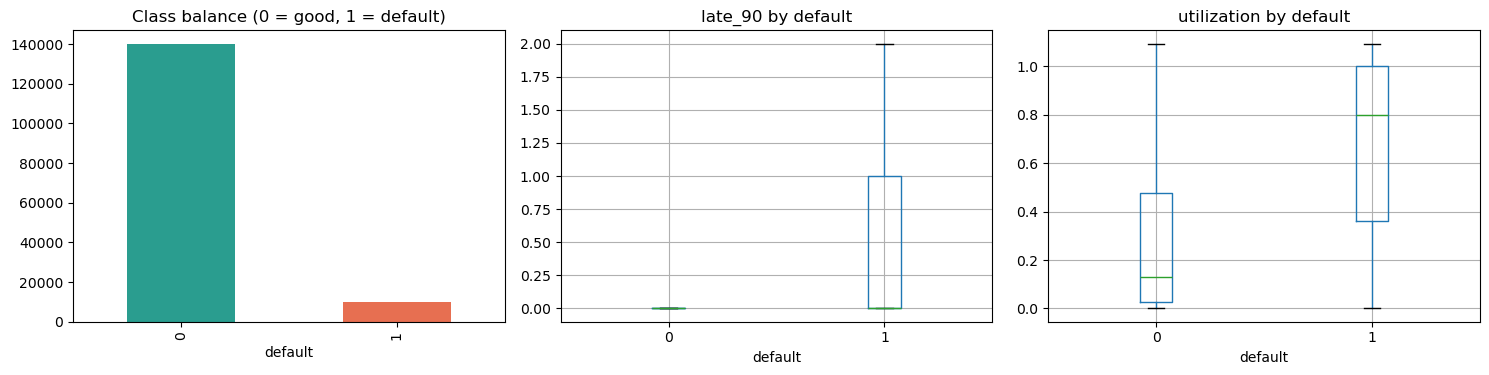

In [4]:
corr_abs = df.corr(numeric_only=True)["default"].drop("default").abs().sort_values(ascending=False)
top2 = list(corr_abs.index[:2])

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
df["default"].value_counts().sort_index().plot.bar(ax=ax[0], color=["#2a9d8f", "#e76f51"])
ax[0].set_title("Class balance (0 = good, 1 = default)")
for a, col in zip(ax[1:], top2):
    lo, hi = df[col].quantile([0.01, 0.99])
    df[df[col].between(lo, hi)].boxplot(column=col, by="default", ax=a, showfliers=False)
    a.set_title(f"{col} by default")
plt.suptitle(""); plt.tight_layout(); plt.show()

## 3. Feature Engineering

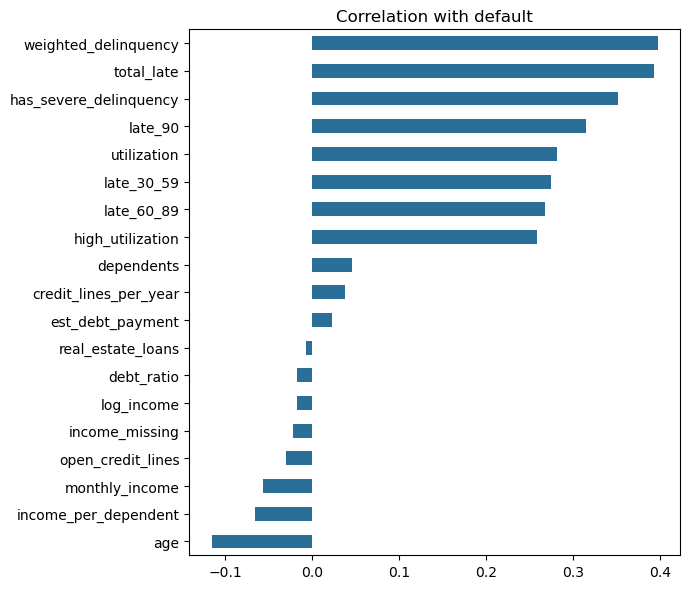

In [5]:
def engineer_features(df):
    d = df.copy()
    if "monthly_income" in d.columns:            # Give Me Some Credit
        d["total_late"] = d["late_30_59"] + d["late_60_89"] + d["late_90"]
        d["weighted_delinquency"] = d["late_30_59"] + 2 * d["late_60_89"] + 3 * d["late_90"]
        d["has_severe_delinquency"] = ((d["late_60_89"].fillna(0) + d["late_90"].fillna(0)) > 0).astype(int)
        d["income_missing"] = d["monthly_income"].isna().astype(int)
        d["log_income"] = np.log1p(d["monthly_income"])
        d["income_per_dependent"] = d["monthly_income"] / (d["dependents"].fillna(0) + 1)
        d["est_debt_payment"] = d["debt_ratio"] * d["monthly_income"]
        d["credit_lines_per_year"] = d["open_credit_lines"] / (d["age"] - 17).clip(lower=1)
        d["high_utilization"] = (d["utilization"] > 0.8).astype(int)
    else:                                         # synthetic data
        inc = d["income"].replace(0, np.nan)
        d["debt_to_income"] = d["monthly_debt"] * 12 / inc
        d["credit_utilization"] = d["credit_used"] / d["credit_limit"].replace(0, np.nan)
        d["loan_to_income"] = d["loan_amount"] / inc
        d["total_late_payments"] = d["late_30"] + d["late_60"] + d["late_90"]
        d["weighted_delinquency"] = d["late_30"] + 2 * d["late_60"] + 3 * d["late_90"]
        d["has_severe_delinquency"] = ((d["late_60"] + d["late_90"]) > 0).astype(int)
        d["avg_credit_per_line"] = d["credit_limit"] / d["num_credit_lines"].replace(0, np.nan)
        d["employment_stability"] = d["employment_years"] / (d["age"] - 18)
        d["log_income"] = np.log1p(d["income"])
    return d.replace([np.inf, -np.inf], np.nan)

data = engineer_features(df)
corr = data.corr(numeric_only=True)["default"].drop("default").sort_values()
corr.plot.barh(figsize=(7, 6), color="#2a6f97", title="Correlation with default")
plt.tight_layout(); plt.show()

## 4. Train / Test Split

In [6]:
X, y = data.drop(columns="default"), data["default"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=SEED)
print(X_train.shape, X_test.shape, f"| train default rate {y_train.mean():.1%}, test {y_test.mean():.1%}")

(112500, 19) (37500, 19) | train default rate 6.7%, test 6.7%


## 5. Models

In [7]:
models = {
    "Logistic Regression": Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
        ("clf", LogisticRegression(max_iter=1000, class_weight="balanced"))]),
    "Decision Tree": Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("clf", DecisionTreeClassifier(max_depth=6, min_samples_leaf=50,
                                       class_weight="balanced", random_state=SEED))]),
    "Random Forest": Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("clf", RandomForestClassifier(n_estimators=200, min_samples_leaf=30,
                                       class_weight="balanced", n_jobs=-1, random_state=SEED))]),
}

cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
probas, preds, rows = {}, {}, []

for name, model in models.items():
    cv_auc = cross_val_score(model, X_train, y_train, cv=cv, scoring="roc_auc").mean()
    model.fit(X_train, y_train)
    p = model.predict_proba(X_test)[:, 1]
    yhat = (p >= 0.5).astype(int)
    probas[name], preds[name] = p, yhat
    rows.append({"Model": name,
                 "Precision": precision_score(y_test, yhat),
                 "Recall": recall_score(y_test, yhat),
                 "F1": f1_score(y_test, yhat),
                 "ROC_AUC": roc_auc_score(y_test, p),
                 "CV_AUC": cv_auc})

results = pd.DataFrame(rows).set_index("Model").round(3)
results

,Precision,Recall,F1,ROC_AUC,CV_AUC
Model,,,,,
Logistic Regression,0.217,0.759,0.337,0.860,0.855
Decision Tree,0.196,0.784,0.313,0.857,0.853
Random Forest,0.273,0.689,0.391,0.865,0.861


## 6. Evaluation

In [8]:
for name in models:
    print(f"=== {name} ===")
    print(classification_report(y_test, preds[name], target_names=["Good", "Default"]))

=== Logistic Regression ===
              precision    recall  f1-score   support

        Good       0.98      0.80      0.88     34994
     Default       0.22      0.76      0.34      2506

    accuracy                           0.80     37500
   macro avg       0.60      0.78      0.61     37500
weighted avg       0.93      0.80      0.85     37500

=== Decision Tree ===
              precision    recall  f1-score   support

        Good       0.98      0.77      0.86     34994
     Default       0.20      0.78      0.31      2506

    accuracy                           0.77     37500
   macro avg       0.59      0.78      0.59     37500
weighted avg       0.93      0.77      0.83     37500

=== Random Forest ===
              precision    recall  f1-score   support

        Good       0.98      0.87      0.92     34994
     Default       0.27      0.69      0.39      2506

    accuracy                           0.86     37500
   macro avg       0.62      0.78      0.65     37500
we

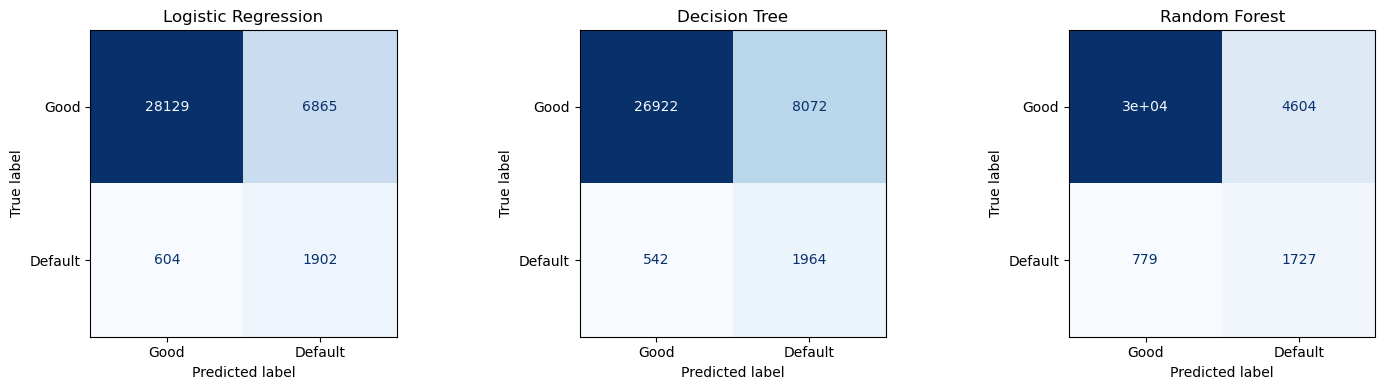

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, name in zip(ax, models):
    ConfusionMatrixDisplay(confusion_matrix(y_test, preds[name]),
                           display_labels=["Good", "Default"]).plot(ax=a, colorbar=False, cmap="Blues")
    a.set_title(name)
plt.tight_layout(); plt.show()

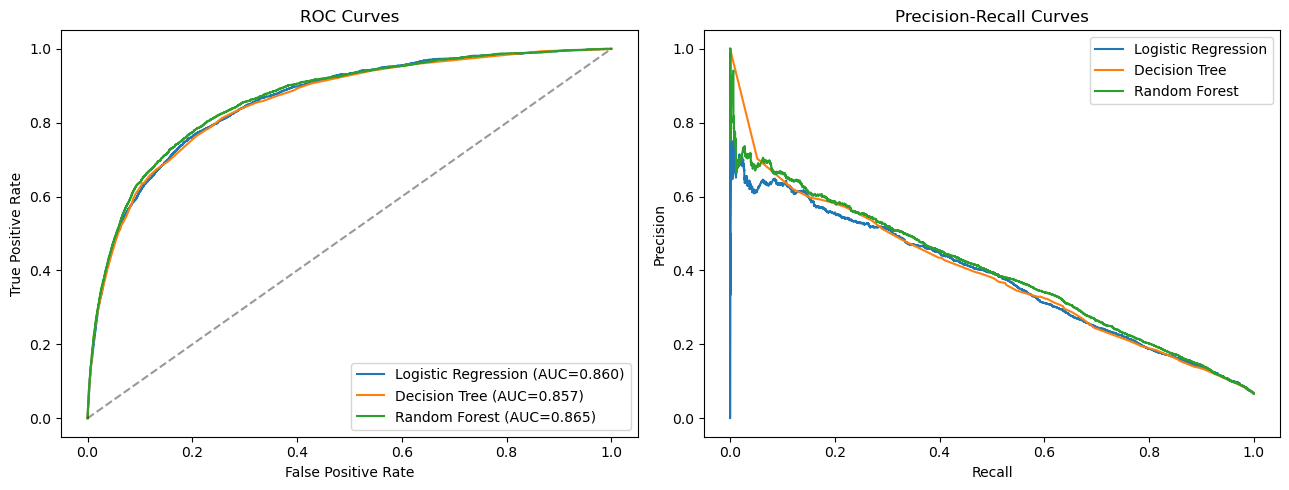

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for name, p in probas.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    ax[0].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, p):.3f})")
    prec, rec, _ = precision_recall_curve(y_test, p)
    ax[1].plot(rec, prec, label=name)
ax[0].plot([0, 1], [0, 1], "k--", alpha=.4)
ax[0].set(xlabel="False Positive Rate", ylabel="True Positive Rate", title="ROC Curves")
ax[1].set(xlabel="Recall", ylabel="Precision", title="Precision-Recall Curves")
ax[0].legend(loc="lower right"); ax[1].legend()
plt.tight_layout(); plt.show()

## 7. Feature Importance & Interpretability

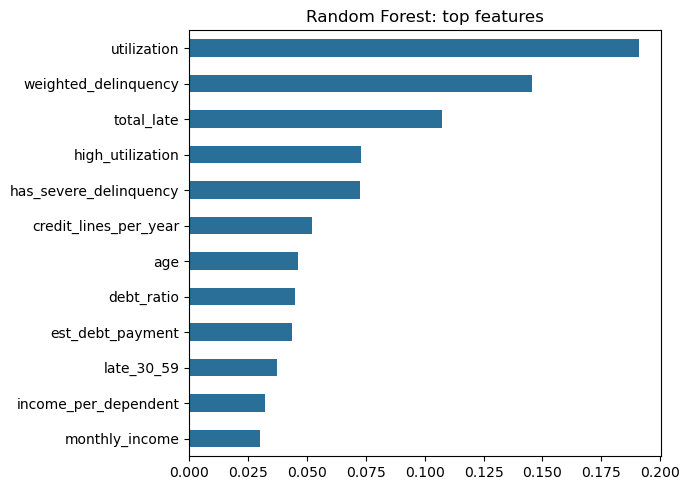

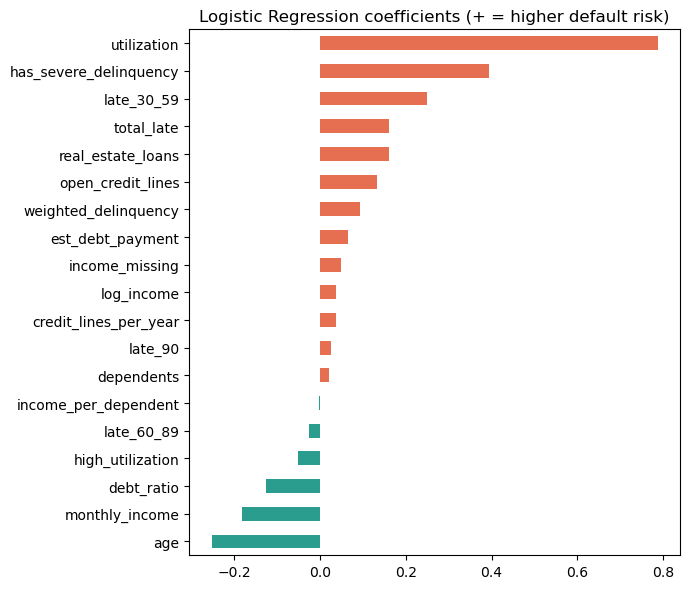

In [11]:
rf = models["Random Forest"].named_steps["clf"]
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values().tail(12)
imp.plot.barh(figsize=(7, 5), color="#2a6f97", title="Random Forest: top features")
plt.tight_layout(); plt.show()

lr = models["Logistic Regression"].named_steps["clf"]
coef = pd.Series(lr.coef_[0], index=X.columns).sort_values()
coef.plot.barh(figsize=(7, 6), color=["#2a9d8f" if c < 0 else "#e76f51" for c in coef],
               title="Logistic Regression coefficients (+ = higher default risk)")
plt.tight_layout(); plt.show()

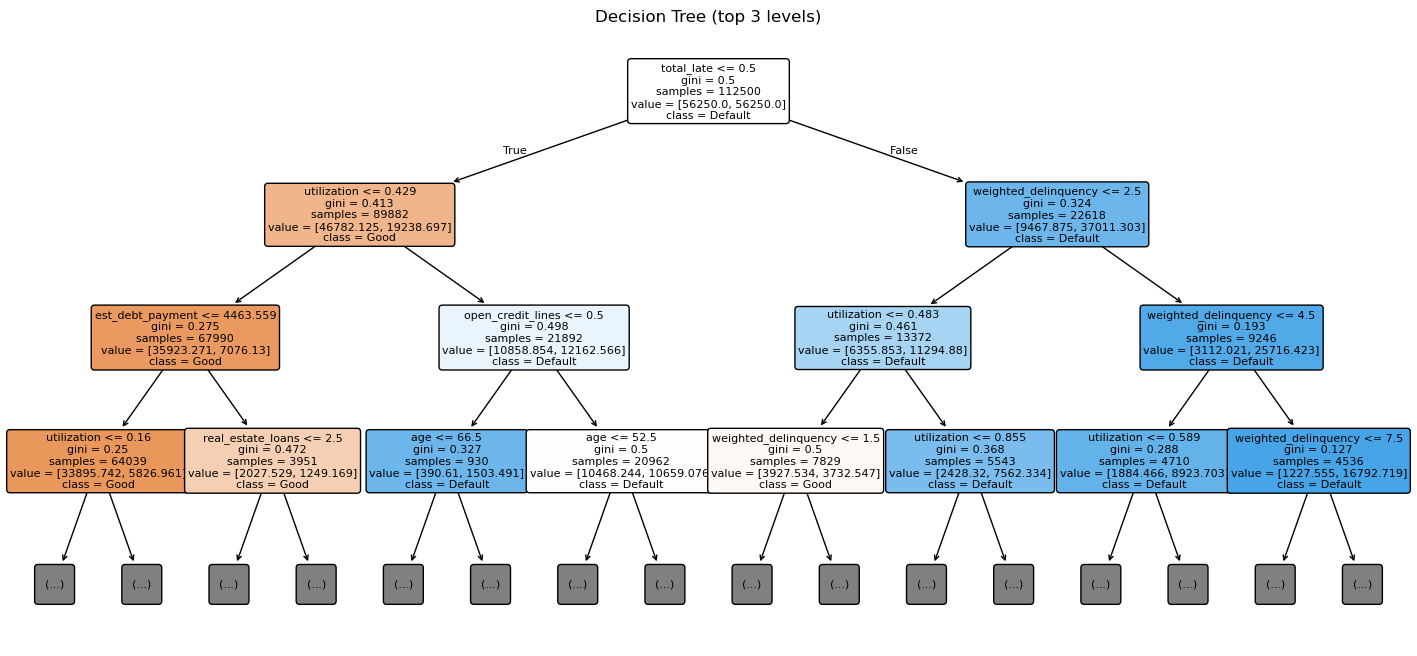

In [12]:
dt = models["Decision Tree"].named_steps["clf"]
plt.figure(figsize=(18, 8))
plot_tree(dt, max_depth=3, feature_names=X.columns, class_names=["Good", "Default"],
          filled=True, rounded=True, fontsize=8)
plt.title("Decision Tree (top 3 levels)"); plt.show()

## 8. Threshold Tuning
The default 0.5 cutoff rarely suits lending. Missing a defaulter (false negative) usually costs far more than rejecting a good customer (false positive). Set the costs below to find the cutoff with the lowest total cost.

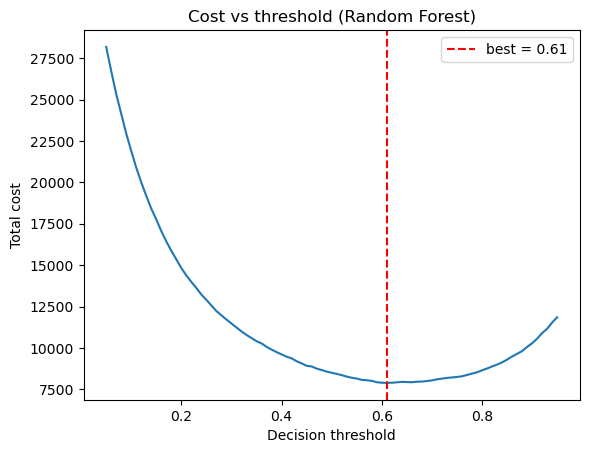

At threshold 0.61: precision=0.333, recall=0.618, F1=0.433


In [13]:
COST_FN = 5   
COST_FP = 1   

best_name = results["ROC_AUC"].idxmax()
p = probas[best_name]
thresholds = np.linspace(0.05, 0.95, 91)
costs = []
for t in thresholds:
    tn, fp, fn, tp = confusion_matrix(y_test, (p >= t).astype(int)).ravel()
    costs.append(COST_FN * fn + COST_FP * fp)

best_t = thresholds[int(np.argmin(costs))]
plt.plot(thresholds, costs); plt.axvline(best_t, color="r", ls="--", label=f"best = {best_t:.2f}")
plt.xlabel("Decision threshold"); plt.ylabel("Total cost"); plt.title(f"Cost vs threshold ({best_name})")
plt.legend(); plt.show()

yhat = (p >= best_t).astype(int)
print(f"At threshold {best_t:.2f}: precision={precision_score(y_test, yhat):.3f}, "
      f"recall={recall_score(y_test, yhat):.3f}, F1={f1_score(y_test, yhat):.3f}")

## 9. Credit Score (300-850)

In [14]:
score = (850 - p * 550).round().astype(int)
scored = pd.DataFrame({"p_default": p.round(3), "credit_score": score, "actual_default": y_test.values})

bands = pd.cut(scored["credit_score"], [299, 580, 670, 740, 800, 850],
               labels=["Poor", "Fair", "Good", "Very Good", "Excellent"])
print(scored.groupby(bands, observed=True)["actual_default"].agg(["count", "mean"])
      .rename(columns={"mean": "actual default rate"}).round(3))
scored.head(10)

              count  actual default rate
credit_score                            
Poor           6505                0.268
Fair           4109                0.073
Good           5305                0.041
Very Good      8986                0.017
Excellent     12595                0.007


,p_default,credit_score,actual_default
0,0.445,605,0
1,0.131,778,0
2,0.293,689,0
3,0.031,833,0
4,0.040,828,0
5,0.544,551,1
6,0.122,783,0
7,0.054,821,0
8,0.268,702,0
9,0.450,602,0


## 10. Conclusions & Next Steps
- Compare the table in Section 5; pick the model by ROC-AUC, then tune the threshold to business costs (Section 8).
- Logistic Regression is the easiest to explain and is the industry standard for regulated scorecards. Random Forest often wins on real, non-linear data.
- Debt-to-income, credit utilization, delinquency history and employment/credit history length are the key drivers.